# 파이썬 머신러닝 완벽가이드 — 5장 회귀 (3)

ESAA YB · ch5.9~5.11 개념 필사

- **5.9** 회귀 실습 — 자전거 대여 수요 예측 (Bike Sharing Demand)
- **5.10** 회귀 실습 — 캐글 주택 가격 예측 (House Prices)
- **5.11** 정리

출처: 저자 깃허브 [wikibook/pymldg-rev](https://github.com/wikibook/pymldg-rev) 5장

## 데이터 준비

두 실습 모두 캐글 대회 데이터를 쓴다. 저자 깃허브에는 노트북만 있고 csv가 없어서,
**같은 데이터를 공개 출처에서 받아 쓴다.** 두 경우 모두 캐글 원본과 행·열이 일치하는 것을 확인했다.

| 실습 | 캐글 파일 | 대체 출처 |
|---|---|---|
| 5.9 자전거 | `bike_train.csv` (10,886행) | UCI Bike Sharing Dataset의 `hour.csv` |
| 5.10 주택 | `house_price.csv` (1,460행 × 81열) | OpenML `house_prices` |

자전거 쪽은 설명이 조금 필요하다. 캐글 대회 데이터는 **UCI 원본에서 매달 1~19일만 잘라낸 것**이고,
온도·습도·풍속이 UCI에서는 0~1로 정규화되어 있다. 그래서 (1) 날짜가 19일 이하인 행만 남기고
(2) 정규화를 되돌리면 캐글 train과 같은 표가 된다. 되돌리는 배수는 UCI 설명 문서에 적힌 값이다
(온도 41, 체감온도 50, 습도 100, 풍속 67).

In [1]:
import io
import zipfile
import urllib.request

import numpy as np
import pandas as pd

# UCI 원본에서 캐글 train과 같은 형태로 복원
_raw = urllib.request.urlopen(
    'https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip', timeout=90).read()
_hour = pd.read_csv(zipfile.ZipFile(io.BytesIO(_raw)).open('hour.csv'))
_hour['dteday'] = pd.to_datetime(_hour['dteday'])

_tr = _hour[_hour['dteday'].dt.day <= 19]          # 캐글 train은 매달 1~19일
pd.DataFrame({
    'datetime': (_tr['dteday'] + pd.to_timedelta(_tr['hr'], unit='h')).dt.strftime('%Y-%m-%d %H:%M:%S'),
    'season': _tr['season'], 'holiday': _tr['holiday'], 'workingday': _tr['workingday'],
    'weather': _tr['weathersit'],
    'temp': (_tr['temp'] * 41).round(2),           # UCI는 0~1로 정규화되어 있다
    'atemp': (_tr['atemp'] * 50).round(3),
    'humidity': (_tr['hum'] * 100).round().astype(int),
    'windspeed': (_tr['windspeed'] * 67).round(4),
    'casual': _tr['casual'], 'registered': _tr['registered'], 'count': _tr['cnt'],
}).to_csv('bike_train.csv', index=False)

print('bike_train.csv 저장 — 캐글 train과 같은 10,886행')

bike_train.csv 저장 — 캐글 train과 같은 10,886행


## 5.9 회귀 실습 — 자전거 대여 수요 예측

워싱턴 DC 자전거 대여 시스템의 **시간당 대여 횟수**를 맞히는 문제다.
날짜·시간과 날씨 정보로 `count`를 예측한다.

평가 지표가 **RMSLE**인 것이 핵심이다. 예측값과 실제값에 로그를 씌운 뒤 RMSE를 계산한다.

$$RMSLE = \sqrt{\frac{1}{N}\sum_{i=1}^{N}\big(\log(y_i+1) - \log(\hat{y}_i+1)\big)^2}$$

로그를 씌우면 **큰 값에서 생긴 오차의 영향이 줄어든다.** 대여 횟수처럼 값의 범위가 넓고
한쪽으로 치우친 데이터에서, 몇 안 되는 큰 값이 점수를 지배하지 않게 하려는 장치다.

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)

bike_df = pd.read_csv('./bike_train.csv')
print(bike_df.shape)
bike_df.head(3)

(10886, 12)


,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,16
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,32,40
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0,5,27,32


In [3]:
bike_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10886 entries, 0 to 10885
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   datetime    10886 non-null  object 
 1   season      10886 non-null  int64  
 2   holiday     10886 non-null  int64  
 3   workingday  10886 non-null  int64  
 4   weather     10886 non-null  int64  
 5   temp        10886 non-null  float64
 6   atemp       10886 non-null  float64
 7   humidity    10886 non-null  int64  
 8   windspeed   10886 non-null  float64
 9   casual      10886 non-null  int64  
 10  registered  10886 non-null  int64  
 11  count       10886 non-null  int64  
dtypes: float64(3), int64(8), object(1)
memory usage: 1020.7+ KB


In [4]:
# 문자열을 datetime 타입으로 변경. 
bike_df['datetime'] = bike_df.datetime.apply(pd.to_datetime)

# datetime 타입에서 년, 월, 일, 시간 추출
bike_df['year'] = bike_df.datetime.apply(lambda x : x.year)
bike_df['month'] = bike_df.datetime.apply(lambda x : x.month)
bike_df['day'] = bike_df.datetime.apply(lambda x : x.day)
bike_df['hour'] = bike_df.datetime.apply(lambda x: x.hour)
bike_df.head(3)

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count,year,month,day,hour
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,16,2011,1,1,0
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,32,40,2011,1,1,1
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0,5,27,32,2011,1,1,2


`datetime` 하나를 년·월·일·시로 쪼갰다. 문자열 그대로는 모델이 쓸 수 없고,
**시간대별 수요 패턴**(출퇴근 시간에 몰리는 등)을 잡으려면 `hour`가 따로 있어야 한다.

In [5]:
drop_columns = ['datetime','casual','registered']
bike_df.drop(drop_columns, axis=1,inplace=True)

`casual`(비회원)과 `registered`(회원)를 지우는 이유는 **둘을 더하면 정답인 `count`가 되기 때문**이다.
그대로 두면 모델이 답을 보고 푸는 셈이다. 미니프로젝트에서 중복 행을 찾아낸 것과 같은 종류의 점검이다.

In [6]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

# log 값 변환 시 NaN등의 이슈로 log() 가 아닌 log1p() 를 이용하여 RMSLE 계산
def rmsle(y, pred):
    log_y = np.log1p(y)
    log_pred = np.log1p(pred)
    squared_error = (log_y - log_pred) ** 2
    rmsle = np.sqrt(np.mean(squared_error))
    return rmsle

# 사이킷런의 mean_square_error() 를 이용하여 RMSE 계산
def rmse(y,pred):
    return np.sqrt(mean_squared_error(y,pred))

# MSE, RMSE, RMSLE 를 모두 계산 
def evaluate_regr(y,pred):
    rmsle_val = rmsle(y,pred)
    rmse_val = rmse(y,pred)
    # MAE 는 scikit learn의 mean_absolute_error() 로 계산
    mae_val = mean_absolute_error(y,pred)
    print('RMSLE: {0:.3f}, RMSE: {1:.3F}, MAE: {2:.3F}'.format(rmsle_val, rmse_val, mae_val))

### 로그 변환, 피처 인코딩, 모델 학습/예측/평가 

In [7]:
from sklearn.model_selection import train_test_split , GridSearchCV
from sklearn.linear_model import LinearRegression , Ridge , Lasso

y_target = bike_df['count']
X_features = bike_df.drop(['count'],axis=1,inplace=False)

X_train, X_test, y_train, y_test = train_test_split(X_features, y_target, test_size=0.3, random_state=0)

lr_reg = LinearRegression()
lr_reg.fit(X_train, y_train)
pred = lr_reg.predict(X_test)

evaluate_regr(y_test ,pred)

RMSLE: 1.165, RMSE: 140.900, MAE: 105.924


RMSLE 1.165. 기준선 없이는 감이 안 오지만, 뒤에서 로그 변환과 인코딩을 거치며
이 숫자가 어떻게 줄어드는지를 따라가면 된다.

In [8]:
def get_top_error_data(y_test, pred, n_tops = 5):
    # DataFrame에 컬럼들로 실제 대여횟수(count)와 예측 값을 서로 비교 할 수 있도록 생성. 
    result_df = pd.DataFrame(y_test.values, columns=['real_count'])
    result_df['predicted_count']= np.round(pred)
    result_df['diff'] = np.abs(result_df['real_count'] - result_df['predicted_count'])
    # 예측값과 실제값이 가장 큰 데이터 순으로 출력. 
    print(result_df.sort_values('diff', ascending=False)[:n_tops])
    
get_top_error_data(y_test,pred,n_tops=5)


      real_count  predicted_count   diff
1618         890            322.0  568.0
966          884            327.0  557.0
3151         798            241.0  557.0
412          745            194.0  551.0
2817         856            310.0  546.0


오차가 큰 상위 5건을 보면 **실제값이 큰 쪽에서 많이 틀린다.**
회귀에서 오류가 큰 데이터를 따로 들여다보는 습관이 중요하다는 걸 보여 주는 대목이다.

<Axes: >

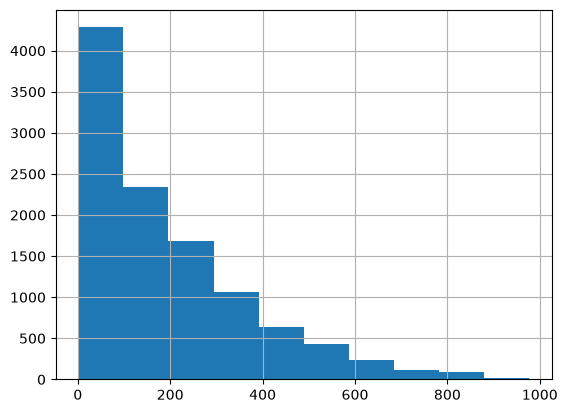

In [9]:
y_target.hist()

<Axes: >

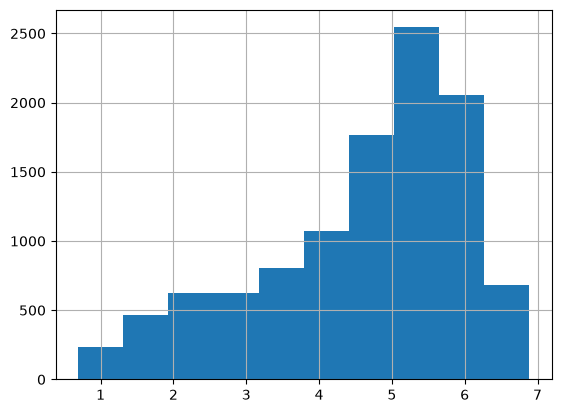

In [10]:
y_log_transform = np.log1p(y_target)
y_log_transform.hist()

원래 `count`는 오른쪽으로 길게 늘어져 있는데, 로그를 씌우니 종 모양에 가까워진다.
**선형 회귀는 타깃이 정규분포에 가까울 때 잘 맞는다.** 그래서 타깃을 로그 변환해 학습하고,
예측값은 `expm1`로 되돌려 평가한다.

In [11]:
# 타겟 컬럼인 count 값을 log1p 로 Log 변환
y_target_log = np.log1p(y_target)

# 로그 변환된 y_target_log를 반영하여 학습/테스트 데이터 셋 분할
X_train, X_test, y_train, y_test = train_test_split(X_features, y_target_log, test_size=0.3, random_state=0)
lr_reg = LinearRegression()
lr_reg.fit(X_train, y_train)
pred = lr_reg.predict(X_test)

# 테스트 데이터 셋의 Target 값은 Log 변환되었으므로 다시 expm1를 이용하여 원래 scale로 변환
y_test_exp = np.expm1(y_test)

# 예측 값 역시 Log 변환된 타겟 기반으로 학습되어 예측되었으므로 다시 exmpl으로 scale변환
pred_exp = np.expm1(pred)

evaluate_regr(y_test_exp ,pred_exp)


RMSLE: 1.017, RMSE: 162.594, MAE: 109.286


<Axes: ylabel='None'>

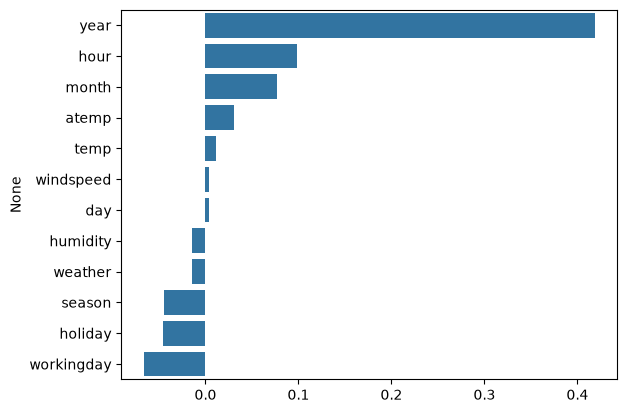

In [12]:
coef = pd.Series(lr_reg.coef_, index=X_features.columns)
coef_sort = coef.sort_values(ascending=False)
sns.barplot(x=coef_sort.values, y=coef_sort.index)

회귀 계수를 보면 `year`가 유독 크다. 2011년보다 2012년에 대여가 많았다는 사실을
모델이 **숫자 크기 그대로** 받아들인 결과다. `year`는 2011·2012라는 **구분값**이지
크기에 의미가 있는 값이 아니다. 다음 셀에서 원-핫 인코딩으로 고친다.

In [13]:
# 'year', month', 'day', hour'등의 피처들을 One Hot Encoding
X_features_ohe = pd.get_dummies(X_features, columns=['year', 'month','day', 'hour', 'holiday',
                                              'workingday','season','weather'])



In [14]:
# 원-핫 인코딩이 적용된 feature 데이터 세트 기반으로 학습/예측 데이터 분할. 
X_train, X_test, y_train, y_test = train_test_split(X_features_ohe, y_target_log,
                                                    test_size=0.3, random_state=0)

# 모델과 학습/테스트 데이터 셋을 입력하면 성능 평가 수치를 반환
def get_model_predict(model, X_train, X_test, y_train, y_test, is_expm1=False):
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    if is_expm1 :
        y_test = np.expm1(y_test)
        pred = np.expm1(pred)
    print('###',model.__class__.__name__,'###')
    evaluate_regr(y_test, pred)
# end of function get_model_predict    

# model 별로 평가 수행
lr_reg = LinearRegression()
ridge_reg = Ridge(alpha=10)
lasso_reg = Lasso(alpha=0.01)

for model in [lr_reg, ridge_reg, lasso_reg]:
    get_model_predict(model,X_train, X_test, y_train, y_test,is_expm1=True)


### LinearRegression ###
RMSLE: 0.590, RMSE: 97.688, MAE: 63.382
### Ridge ###
RMSLE: 0.590, RMSE: 98.529, MAE: 63.893
### Lasso ###
RMSLE: 0.635, RMSE: 113.219, MAE: 72.803


원-핫 인코딩 후 RMSLE가 1.017에서 0.590 수준으로 크게 떨어진다.
**숫자처럼 생겼지만 실제로는 범주인 변수**를 제대로 다루는 것만으로 얻은 개선이다.

<Axes: ylabel='None'>

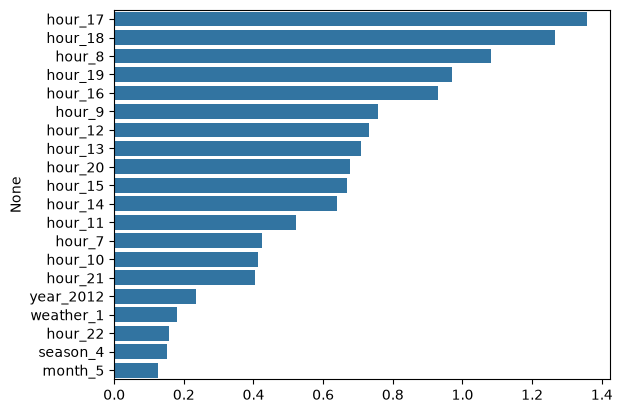

In [15]:
coef = pd.Series(lr_reg.coef_ , index=X_features_ohe.columns)
coef_sort = coef.sort_values(ascending=False)[:20]
sns.barplot(x=coef_sort.values , y=coef_sort.index)


In [16]:
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

# 랜덤 포레스트, GBM, XGBoost, LightGBM model 별로 평가 수행
rf_reg = RandomForestRegressor(n_estimators=500)
gbm_reg = GradientBoostingRegressor(n_estimators=500)
xgb_reg = XGBRegressor(n_estimators=500)
lgbm_reg = LGBMRegressor(n_estimators=500)

for model in [rf_reg, gbm_reg, xgb_reg, lgbm_reg]:
    # XGBoost의 경우 DataFrame이 입력 될 경우 버전에 따라 오류 발생 가능. ndarray로 변환.
    get_model_predict(model,X_train.values, X_test.values, y_train.values, y_test.values,is_expm1=True)

### RandomForestRegressor ###
RMSLE: 0.354, RMSE: 50.310, MAE: 31.171


### GradientBoostingRegressor ###
RMSLE: 0.330, RMSE: 53.347, MAE: 32.744


### XGBRegressor ###
RMSLE: 0.339, RMSE: 51.475, MAE: 31.357


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000411 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 348
[LightGBM] [Info] Number of data points in the train set: 7620, number of used features: 72
[LightGBM] [Info] Start training from score 4.582043


### LGBMRegressor ###
RMSLE: 0.319, RMSE: 47.215, MAE: 29.029


트리 계열로 바꾸면 RMSLE가 0.35 안팎까지 내려간다. 선형 모델과의 격차가 크다.
미니프로젝트에서 로지스틱 회귀가 트리에 14%p 밀렸던 것과 같은 구도다 —
**시간대·계절·날씨가 서로 맞물려 작용하는 관계**를 직선 하나로는 담지 못한다.

## 5.10 회귀 실습 — 캐글 주택 가격 예측

미국 아이오와주 에임스의 **주택 매매가**를 맞히는 문제다. 79개 변수로 `SalePrice`를 예측한다.

5.9와 달리 **변수가 많고 결측치도 많다.** 그래서 모델보다 전처리에서 점수가 많이 갈린다.
아래 순서로 하나씩 효과를 확인한다.

1. 타깃 로그 변환 → 2. 결측치·불필요 변수 처리 → 3. 원-핫 인코딩
→ 4. 하이퍼파라미터 튜닝 → 5. 왜곡된 변수 로그 변환 → 6. 이상치 제거
→ 7. 회귀 트리 → 8. 예측값 혼합 → 9. 스태킹

저자 코드는 `house_price.csv`를 읽는다. 같은 데이터를 OpenML에서 받아
**같은 이름의 데이터프레임**을 만들어 둔다. 1,460행 × 81열, `PoolQC` 결측 1,453건까지 캐글 원본과 같다.

In [17]:
from sklearn.datasets import fetch_openml

_h = fetch_openml(name='house_prices', version=1, as_frame=True, parser='auto')
house_df_org = _h.data.copy()
house_df_org['SalePrice'] = _h.target.astype(float)
house_df = house_df_org.copy()

print('주택 데이터:', house_df.shape)
house_df.head(3)

주택 데이터: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500.0
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500.0
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500.0


In [18]:
print('데이터 세트의 Shape:', house_df.shape)
print('\n전체 feature 들의 type \n',house_df.dtypes.value_counts())
isnull_series = house_df.isnull().sum()
print('\nNull 컬럼과 그 건수:\n ', isnull_series[isnull_series > 0].sort_values(ascending=False))

데이터 세트의 Shape: (1460, 81)

전체 feature 들의 type 
 object     43
int64      34
float64     4
Name: count, dtype: int64

Null 컬럼과 그 건수:
  PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
FireplaceQu      690
LotFrontage      259
GarageCond        81
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
BsmtFinType2      38
BsmtExposure      38
BsmtCond          37
BsmtQual          37
BsmtFinType1      37
MasVnrType         8
MasVnrArea         8
Electrical         1
dtype: int64


결측치가 1,453건인 `PoolQC`(수영장 품질)처럼 **거의 비어 있는 변수**가 보인다.
수영장이 없는 집이 대부분이라 비어 있는 것이지 기록이 누락된 게 아니다.

C:\Users\user\AppData\Local\Temp\ipykernel_26496\3253124377.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(house_df['SalePrice'])


<Axes: title={'center': 'Original Sale Price Histogram'}, xlabel='SalePrice', ylabel='Density'>

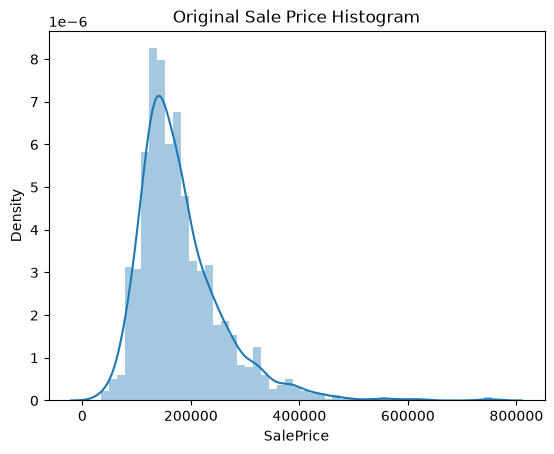

In [19]:
plt.title('Original Sale Price Histogram')
sns.distplot(house_df['SalePrice'])

C:\Users\user\AppData\Local\Temp\ipykernel_26496\1042888139.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(log_SalePrice)


<Axes: title={'center': 'Log Transformed Sale Price Histogram'}, xlabel='SalePrice', ylabel='Density'>

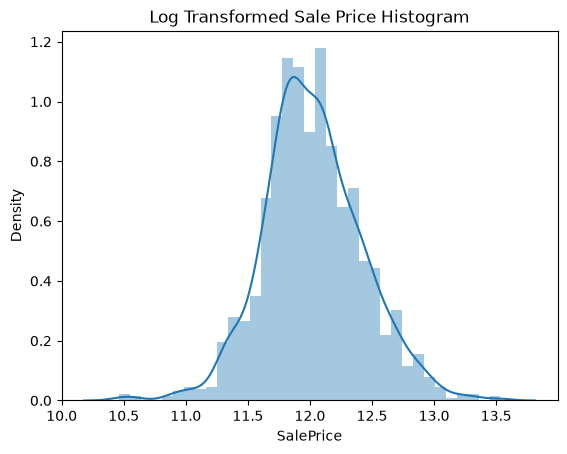

In [20]:
plt.title('Log Transformed Sale Price Histogram')
log_SalePrice = np.log1p(house_df['SalePrice'])
sns.distplot(log_SalePrice)

`SalePrice`도 오른쪽으로 치우쳐 있어 로그 변환하면 정규분포에 가까워진다.
5.9의 `count`와 같은 처리다.

In [21]:
# SalePrice 로그 변환
original_SalePrice = house_df['SalePrice']
house_df['SalePrice'] = np.log1p(house_df['SalePrice'])

# Null 이 너무 많은 컬럼들과 불필요한 컬럼 삭제
house_df.drop(['Id','PoolQC' , 'MiscFeature', 'Alley', 'Fence','FireplaceQu'], axis=1 , inplace=True)
# Drop 하지 않는 숫자형 Null컬럼들은 평균값으로 대체
house_df.fillna(house_df.mean(numeric_only=True), inplace=True)  # pandas 2.x: 숫자형만 평균 계산

# Null 값이 있는 피처명과 타입을 추출
null_column_count = house_df.isnull().sum()[house_df.isnull().sum() > 0]
print('## Null 피처의 Type :\n', house_df.dtypes[null_column_count.index])


## Null 피처의 Type :
 MasVnrType      object
BsmtQual        object
BsmtCond        object
BsmtExposure    object
BsmtFinType1    object
BsmtFinType2    object
Electrical      object
GarageType      object
GarageFinish    object
GarageQual      object
GarageCond      object
dtype: object


결측이 너무 많은 다섯 개 변수와 `Id`를 지우고, 남은 숫자형 결측은 평균으로 채웠다.
**결측치를 메우는 것과 변수를 버리는 것은 다른 판단**이다 — 여기서는 비어 있는 비율로 갈랐다.

In [22]:
print('get_dummies() 수행 전 데이터 Shape:', house_df.shape)
house_df_ohe = pd.get_dummies(house_df)
print('get_dummies() 수행 후 데이터 Shape:', house_df_ohe.shape)

null_column_count = house_df_ohe.isnull().sum()[house_df_ohe.isnull().sum() > 0]
print('## Null 피처의 Type :\n', house_df_ohe.dtypes[null_column_count.index])


get_dummies() 수행 전 데이터 Shape: (1460, 75)
get_dummies() 수행 후 데이터 Shape: (1460, 271)
## Null 피처의 Type :
 Series([], dtype: object)


원-핫 인코딩으로 열이 75개에서 271개로 늘었다. 범주형이 많은 데이터의 전형적인 모습이다.

### 선형 회귀 모델의 학습/예측/평가

In [23]:
def get_rmse(model):
    pred = model.predict(X_test)
    mse = mean_squared_error(y_test , pred)
    rmse = np.sqrt(mse)
    print('{0} 로그 변환된 RMSE: {1}'.format(model.__class__.__name__,np.round(rmse, 3)))
    return rmse

def get_rmses(models):
    rmses = [ ]
    for model in models:
        rmse = get_rmse(model)
        rmses.append(rmse)
    return rmses

In [24]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

y_target = house_df_ohe['SalePrice']
X_features = house_df_ohe.drop('SalePrice',axis=1, inplace=False)

X_train, X_test, y_train, y_test = train_test_split(X_features, y_target, test_size=0.2, random_state=156)

# LinearRegression, Ridge, Lasso 학습, 예측, 평가
lr_reg = LinearRegression()
lr_reg.fit(X_train, y_train)

ridge_reg = Ridge()
ridge_reg.fit(X_train, y_train)

lasso_reg = Lasso()
lasso_reg.fit(X_train, y_train)

models = [lr_reg, ridge_reg, lasso_reg]
get_rmses(models)


LinearRegression 로그 변환된 RMSE: 0.132
Ridge 로그 변환된 RMSE: 0.128
Lasso 로그 변환된 RMSE: 0.176


[np.float64(0.13189576579154538),
 np.float64(0.12750846334053048),
 np.float64(0.17628250556471403)]

In [25]:
def get_top_bottom_coef(model):
    # coef_ 속성을 기반으로 Series 객체를 생성. index는 컬럼명. 
    coef = pd.Series(model.coef_, index=X_features.columns)
    
    # + 상위 10개 , - 하위 10개 coefficient 추출하여 반환.
    coef_high = coef.sort_values(ascending=False).head(10)
    coef_low = coef.sort_values(ascending=False).tail(10)
    return coef_high, coef_low


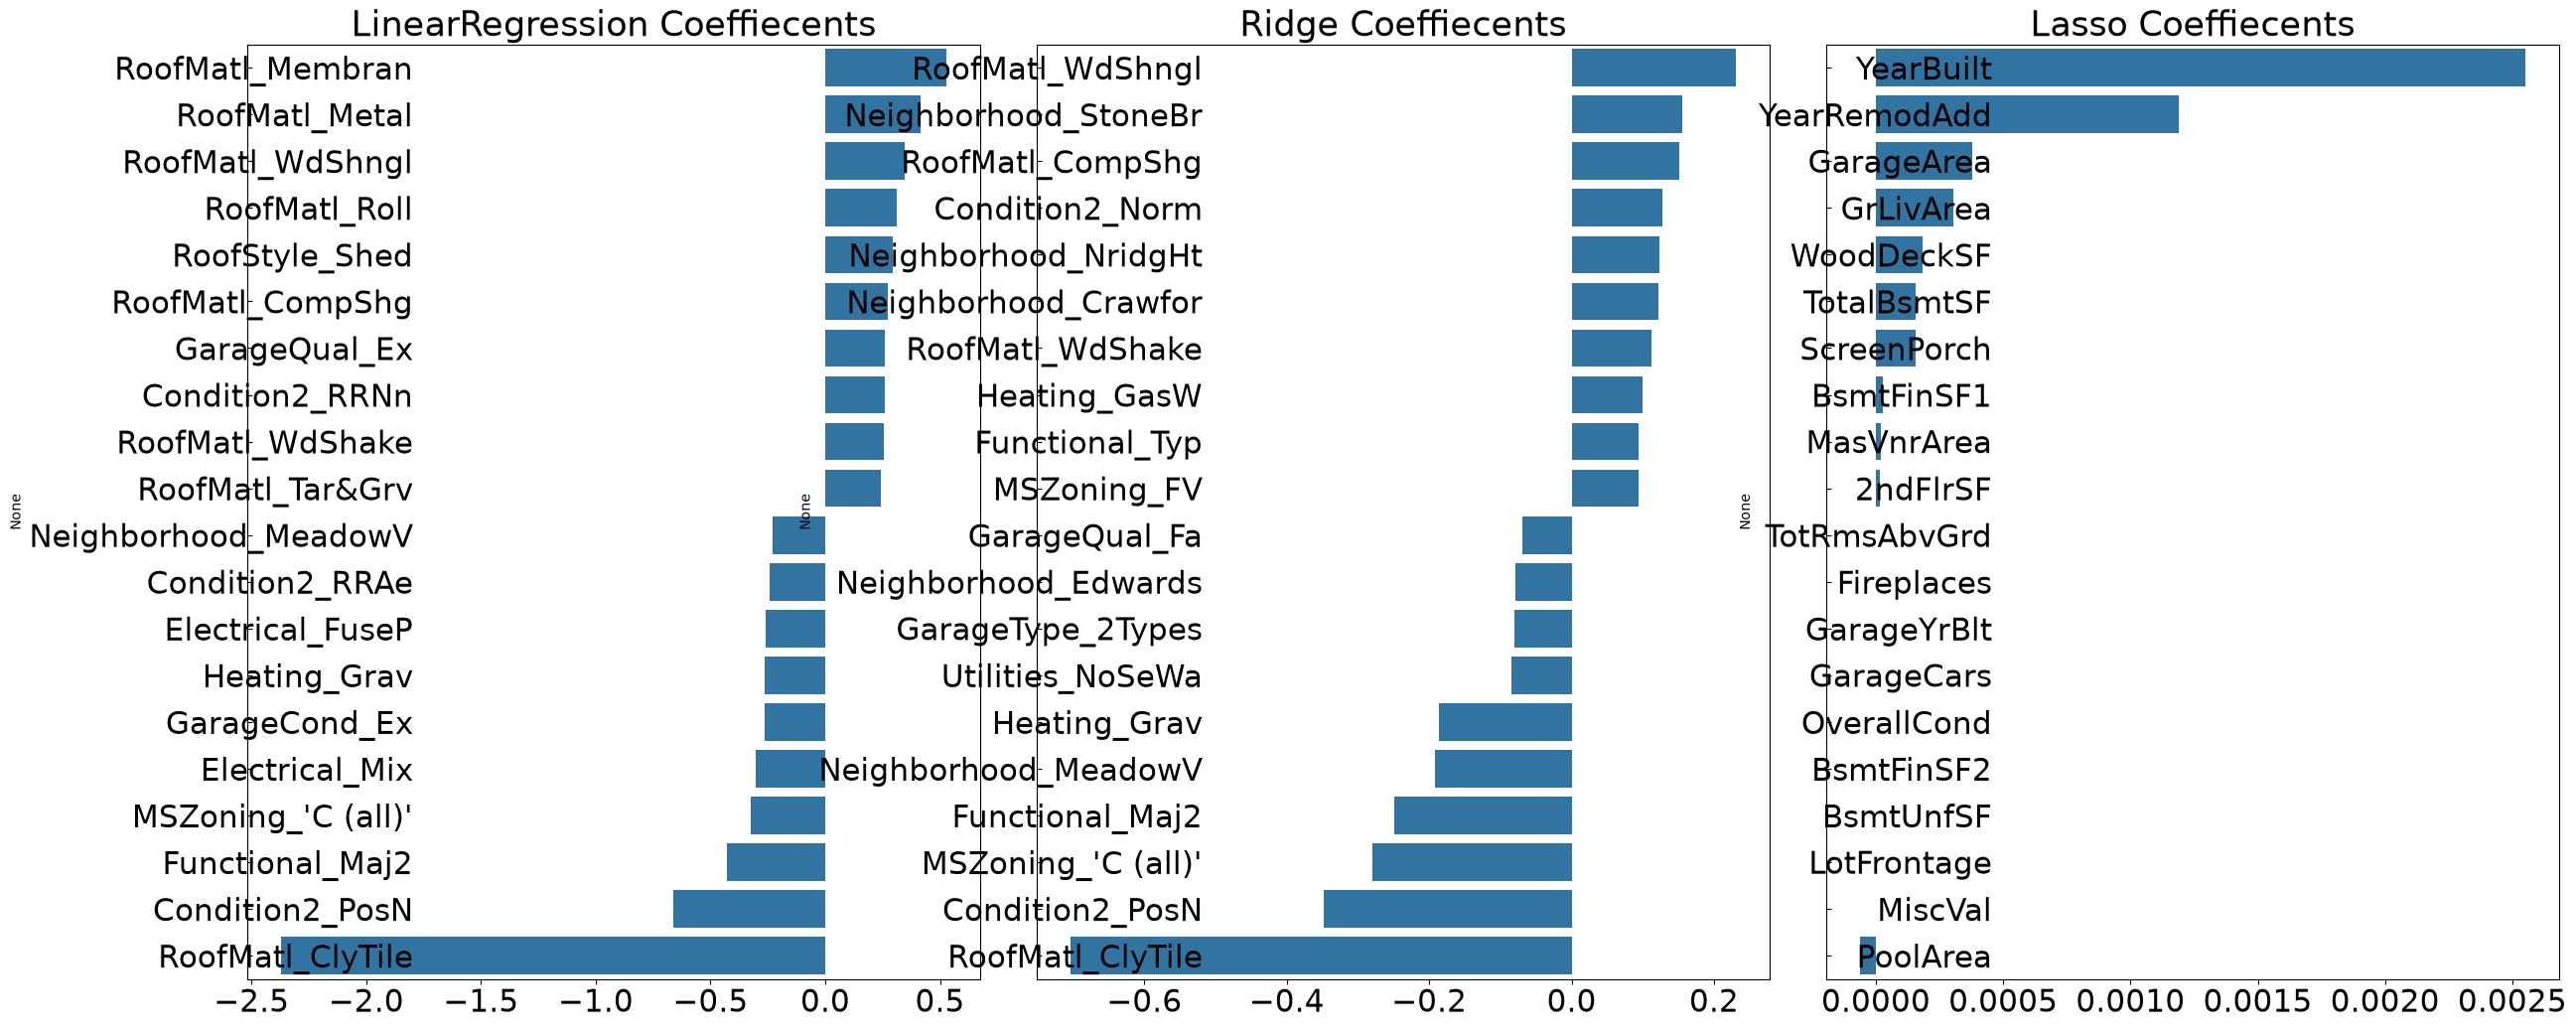

In [26]:
def visualize_coefficient(models):
    # 3개 회귀 모델의 시각화를 위해 3개의 컬럼을 가지는 subplot 생성
    fig, axs = plt.subplots(figsize=(24,10),nrows=1, ncols=3)
    fig.tight_layout() 
    # 입력인자로 받은 list객체인 models에서 차례로 model을 추출하여 회귀 계수 시각화. 
    for i_num, model in enumerate(models):
        # 상위 10개, 하위 10개 회귀 계수를 구하고, 이를 판다스 concat으로 결합. 
        coef_high, coef_low = get_top_bottom_coef(model)
        coef_concat = pd.concat( [coef_high , coef_low] )
        # 순차적으로 ax subplot에 barchar로 표현. 한 화면에 표현하기 위해 tick label 위치와 font 크기 조정. 
        axs[i_num].set_title(model.__class__.__name__+' Coeffiecents', size=25)
        axs[i_num].tick_params(axis="y",direction="in", pad=-120)
        for label in (axs[i_num].get_xticklabels() + axs[i_num].get_yticklabels()):
            label.set_fontsize(22)
        sns.barplot(x=coef_concat.values, y=coef_concat.index , ax=axs[i_num])

# 앞 예제에서 학습한 lr_reg, ridge_reg, lasso_reg 모델의 회귀 계수 시각화.    
models = [lr_reg, ridge_reg, lasso_reg]
visualize_coefficient(models)


In [27]:
from sklearn.model_selection import cross_val_score

def get_avg_rmse_cv(models):
    for model in models:
        # 분할하지 않고 전체 데이터로 cross_val_score( ) 수행. 모델별 CV RMSE값과 평균 RMSE 출력
        rmse_list = np.sqrt(-cross_val_score(model, X_features, y_target,
                                             scoring="neg_mean_squared_error", cv = 5))
        rmse_avg = np.mean(rmse_list)
        print('\n{0} CV RMSE 값 리스트: {1}'.format( model.__class__.__name__, np.round(rmse_list, 3)))
        print('{0} CV 평균 RMSE 값: {1}'.format( model.__class__.__name__, np.round(rmse_avg, 3)))

# 앞 예제에서 학습한 lr_reg, ridge_reg, lasso_reg 모델의 CV RMSE값 출력           
models = [lr_reg, ridge_reg, lasso_reg]
get_avg_rmse_cv(models)


LinearRegression CV RMSE 값 리스트: [0.135 0.165 0.168 0.111 0.198]
LinearRegression CV 평균 RMSE 값: 0.155



Ridge CV RMSE 값 리스트: [0.117 0.154 0.142 0.117 0.189]
Ridge CV 평균 RMSE 값: 0.144



Lasso CV RMSE 값 리스트: [0.161 0.204 0.177 0.181 0.265]
Lasso CV 평균 RMSE 값: 0.198


교차검증으로 보니 라쏘가 릿지보다 눈에 띄게 나쁘다. `alpha` 기본값(1)이 이 데이터에는
**너무 센 규제**였기 때문이다. 다음 셀에서 `alpha`를 탐색하면 역전된다.

* 하이퍼 파라미터 튜닝

In [28]:

from sklearn.model_selection import GridSearchCV

def print_best_params(model, params):
    grid_model = GridSearchCV(model, param_grid=params, 
                              scoring='neg_mean_squared_error', cv=5)
    grid_model.fit(X_features, y_target)
    rmse = np.sqrt(-1* grid_model.best_score_)
    print('{0} 5 CV 시 최적 평균 RMSE 값: {1}, 최적 alpha:{2}'.format(model.__class__.__name__,
                                        np.round(rmse, 4), grid_model.best_params_))
    return grid_model.best_estimator_

ridge_params = { 'alpha':[0.05, 0.1, 1, 5, 8, 10, 12, 15, 20] }
lasso_params = { 'alpha':[0.001, 0.005, 0.008, 0.05, 0.03, 0.1, 0.5, 1,5, 10] }
best_rige = print_best_params(ridge_reg, ridge_params)
best_lasso = print_best_params(lasso_reg, lasso_params)


Ridge 5 CV 시 최적 평균 RMSE 값: 0.1418, 최적 alpha:{'alpha': 12}


Lasso 5 CV 시 최적 평균 RMSE 값: 0.142, 최적 alpha:{'alpha': 0.001}


릿지 `alpha=12`, 라쏘 `alpha=0.001`이 최적으로 나왔다. 라쏘의 최적값이 기본값의
**1/1000**이다. 5.6에서 본 "규제가 과하면 오히려 나빠진다"가 실제로 드러난 장면이다.

LinearRegression 로그 변환된 RMSE: 0.132
Ridge 로그 변환된 RMSE: 0.124
Lasso 로그 변환된 RMSE: 0.12


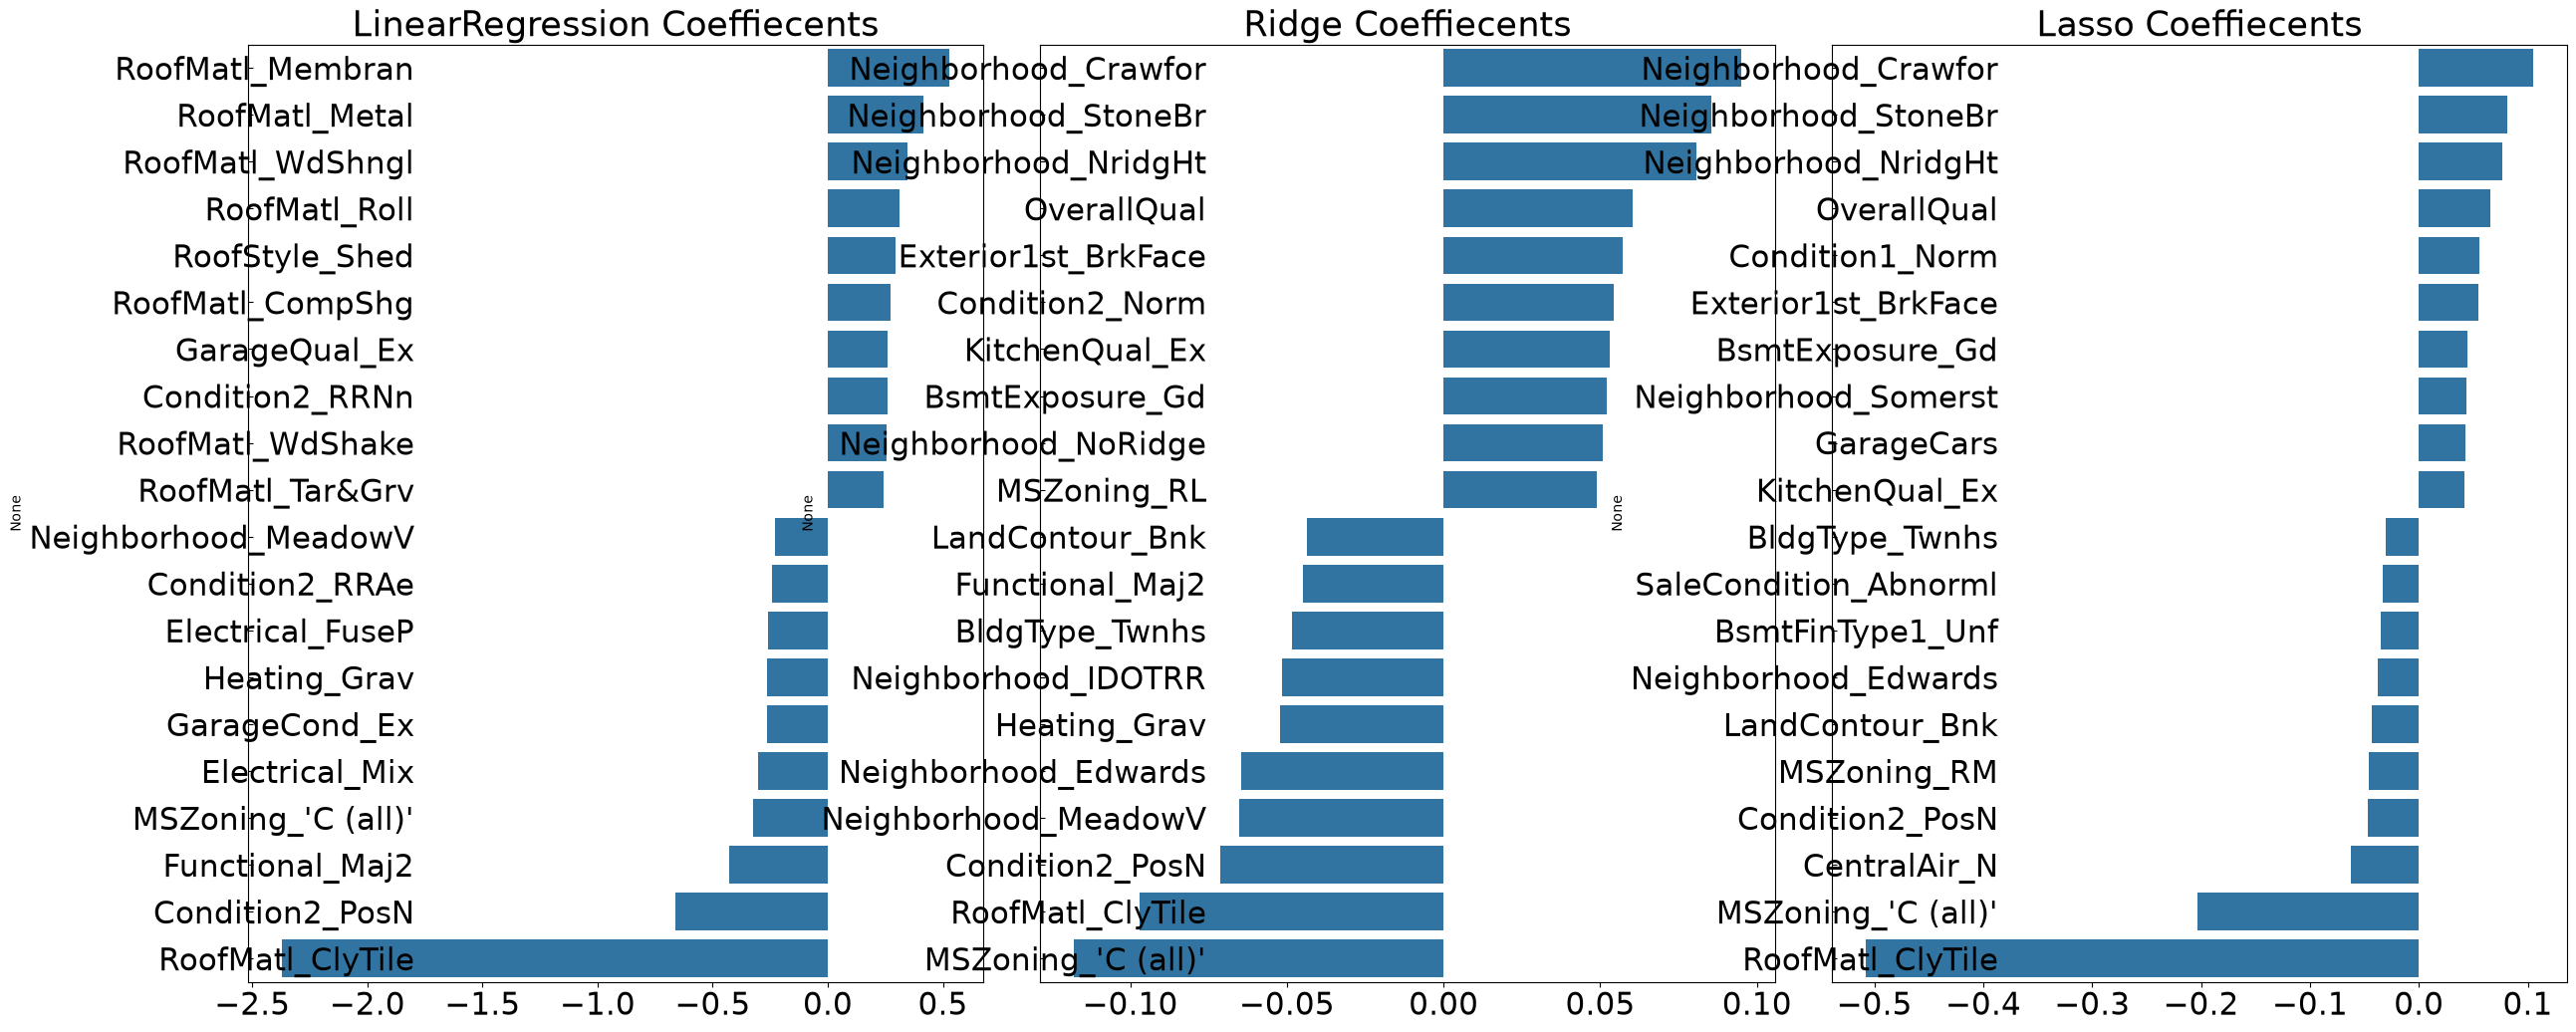

In [29]:
# 앞의 최적화 alpha값으로 학습데이터로 학습, 테스트 데이터로 예측 및 평가 수행. 
lr_reg = LinearRegression()
lr_reg.fit(X_train, y_train)
ridge_reg = Ridge(alpha=12)
ridge_reg.fit(X_train, y_train)
lasso_reg = Lasso(alpha=0.001)
lasso_reg.fit(X_train, y_train)

# 모든 모델의 RMSE 출력
models = [lr_reg, ridge_reg, lasso_reg]
get_rmses(models)

# 모든 모델의 회귀 계수 시각화 
models = [lr_reg, ridge_reg, lasso_reg]
visualize_coefficient(models)

* 데이터 왜곡 로그 변환 후 성능 평가

In [30]:
from scipy.stats import skew

# object가 아닌 숫자형 피쳐의 컬럼 index 객체 추출.
features_index = house_df.dtypes[house_df.dtypes != 'object'].index
# house_df에 컬럼 index를 [ ]로 입력하면 해당하는 컬럼 데이터 셋 반환. apply lambda로 skew( )호출 
skew_features = house_df[features_index].apply(lambda x : skew(x))
# skew 정도가 1 이상인 컬럼들만 추출. 
skew_features_top = skew_features[skew_features > 1]
print(skew_features_top.sort_values(ascending=False))

MiscVal          24.451640
PoolArea         14.813135
LotArea          12.195142
3SsnPorch        10.293752
LowQualFinSF      9.002080
KitchenAbvGr      4.483784
BsmtFinSF2        4.250888
ScreenPorch       4.117977
BsmtHalfBath      4.099186
EnclosedPorch     3.086696
MasVnrArea        2.673661
LotFrontage       2.382499
OpenPorchSF       2.361912
BsmtFinSF1        1.683771
WoodDeckSF        1.539792
TotalBsmtSF       1.522688
MSSubClass        1.406210
1stFlrSF          1.375342
GrLivArea         1.365156
dtype: float64


왜도가 1을 넘는 변수들이다. `MiscVal`, `PoolArea`처럼 대부분 0이고 일부만 큰 값을 갖는
변수가 상위에 있다. **타깃만이 아니라 입력 변수도 로그 변환 대상**이 된다.

In [31]:
house_df[skew_features_top.index] = np.log1p(house_df[skew_features_top.index])

In [32]:
# Skew가 높은 피처들을 로그 변환 했으므로 다시 원-핫 인코딩 적용 및 피처/타겟 데이터 셋 생성,
house_df_ohe = pd.get_dummies(house_df)
y_target = house_df_ohe['SalePrice']
X_features = house_df_ohe.drop('SalePrice',axis=1, inplace=False)
X_train, X_test, y_train, y_test = train_test_split(X_features, y_target, test_size=0.2, random_state=156)

# 피처들을 로그 변환 후 다시 최적 하이퍼 파라미터와 RMSE 출력
ridge_params = { 'alpha':[0.05, 0.1, 1, 5, 8, 10, 12, 15, 20] }
lasso_params = { 'alpha':[0.001, 0.005, 0.008, 0.05, 0.03, 0.1, 0.5, 1,5, 10] }
best_ridge = print_best_params(ridge_reg, ridge_params)
best_lasso = print_best_params(lasso_reg, lasso_params)

Ridge 5 CV 시 최적 평균 RMSE 값: 0.1275, 최적 alpha:{'alpha': 10}


Lasso 5 CV 시 최적 평균 RMSE 값: 0.1252, 최적 alpha:{'alpha': 0.001}


LinearRegression 로그 변환된 RMSE: 0.128
Ridge 로그 변환된 RMSE: 0.122
Lasso 로그 변환된 RMSE: 0.119


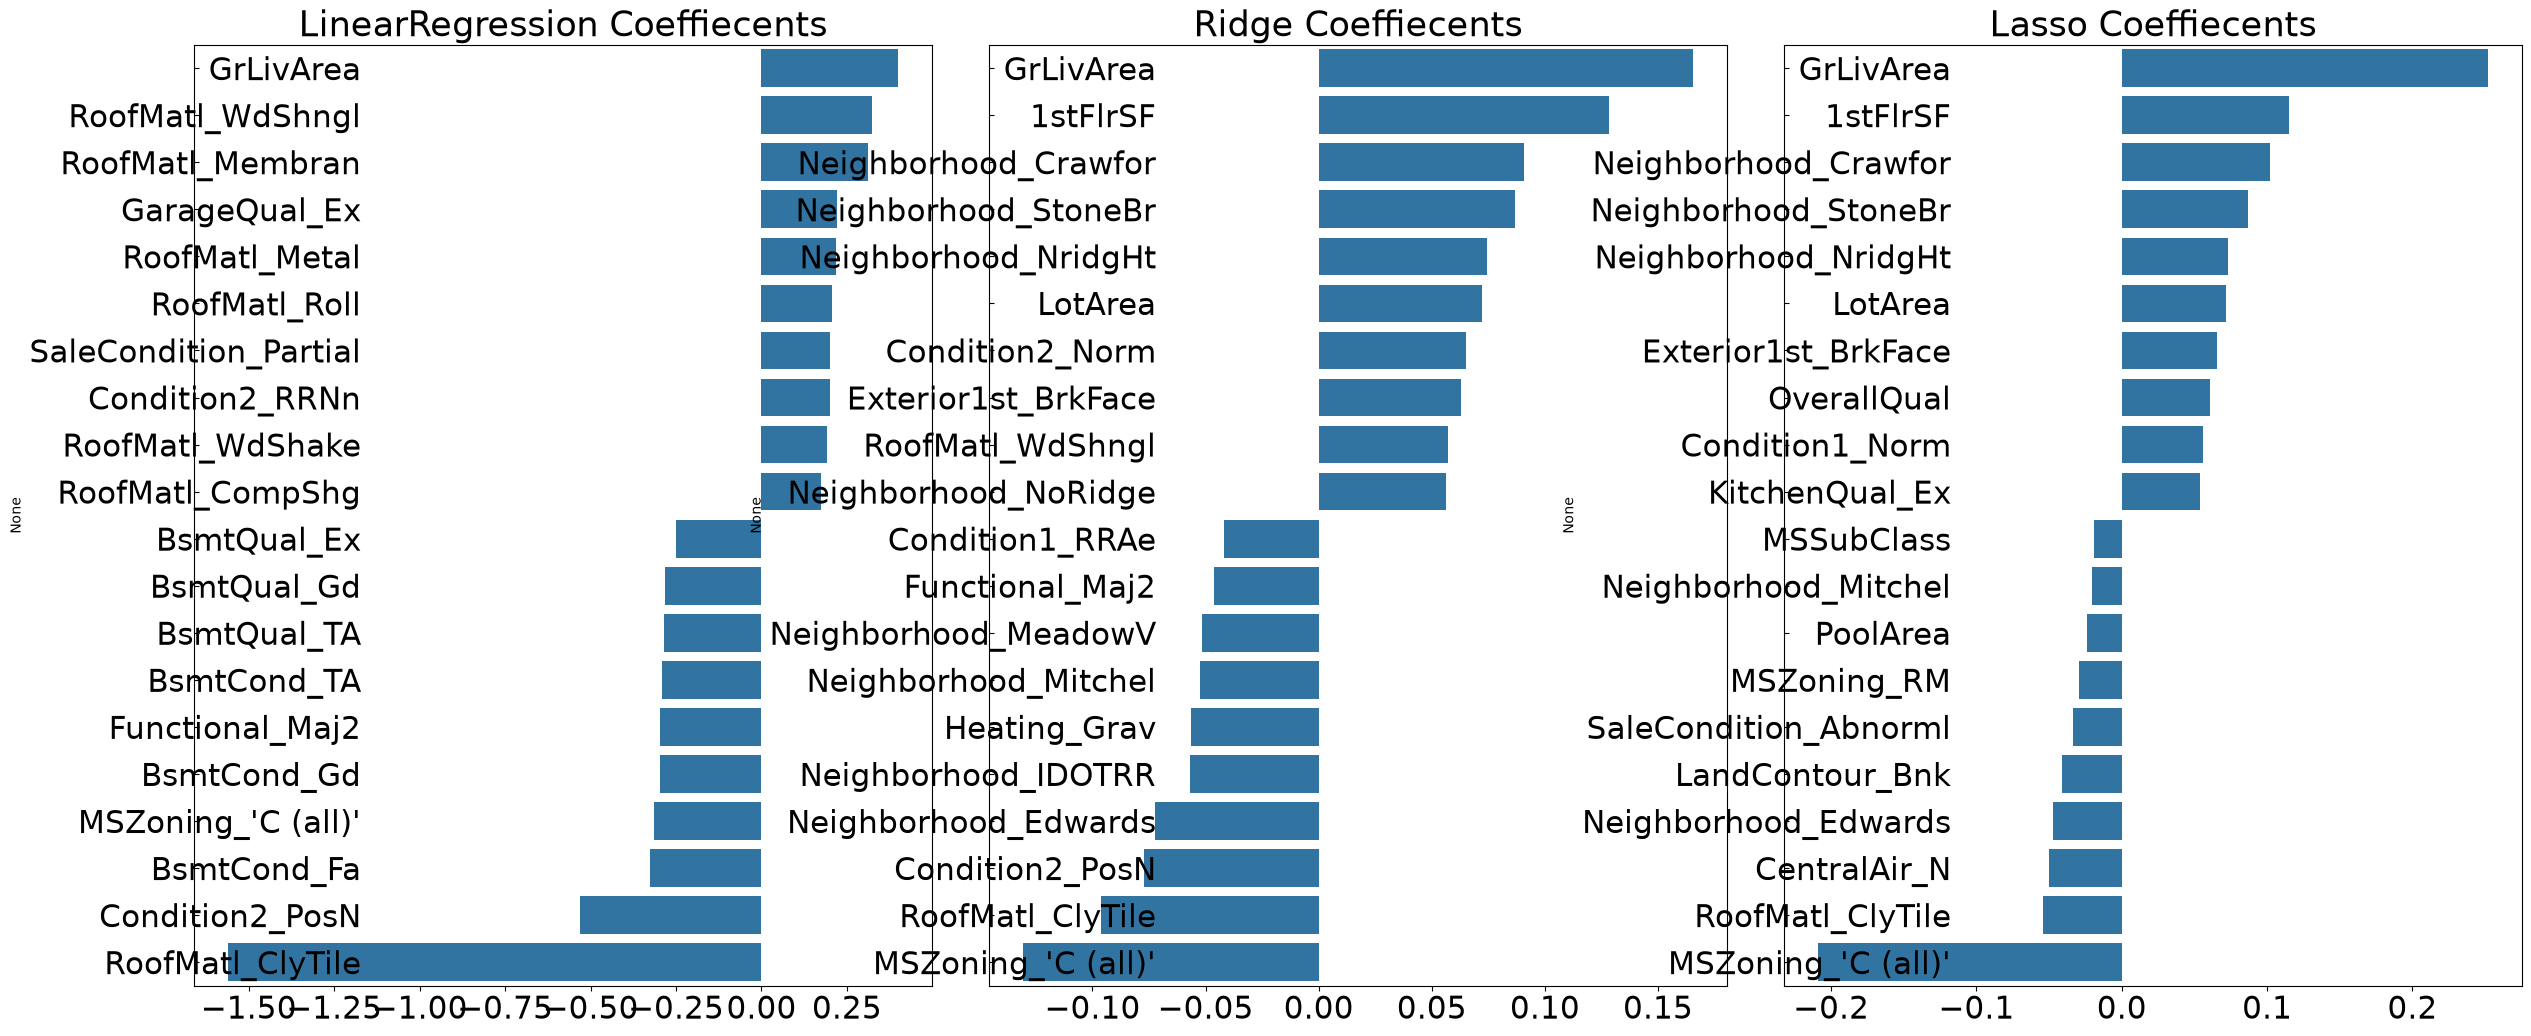

In [33]:
# 앞의 최적화 alpha값으로 학습데이터로 학습, 테스트 데이터로 예측 및 평가 수행. 
lr_reg = LinearRegression()
lr_reg.fit(X_train, y_train)
ridge_reg = Ridge(alpha=10)
ridge_reg.fit(X_train, y_train)
lasso_reg = Lasso(alpha=0.001)
lasso_reg.fit(X_train, y_train)

# 모든 모델의 RMSE 출력
models = [lr_reg, ridge_reg, lasso_reg]
get_rmses(models)

# 모든 모델의 회귀 계수 시각화 
models = [lr_reg, ridge_reg, lasso_reg]
visualize_coefficient(models)

* 이상치 제거

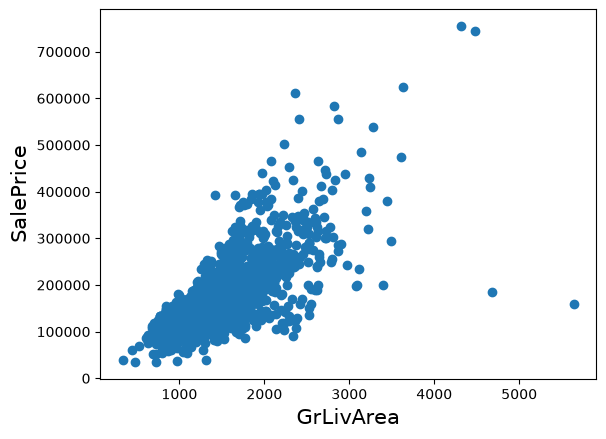

In [34]:
plt.scatter(x = house_df_org['GrLivArea'], y = house_df_org['SalePrice'])
plt.ylabel('SalePrice', fontsize=15)
plt.xlabel('GrLivArea', fontsize=15)
plt.show()


`GrLivArea`(거주 면적)가 아주 큰데 가격은 낮은 점 두 개가 눈에 띈다.
면적이 넓으면 비싸다는 일반적인 경향에서 크게 벗어난 집이다.

In [35]:
# GrLivArea와 SalePrice 모두 로그 변환되었으므로 이를 반영한 조건 생성. 
cond1 = house_df_ohe['GrLivArea'] > np.log1p(4000)
cond2 = house_df_ohe['SalePrice'] < np.log1p(500000)
outlier_index = house_df_ohe[cond1 & cond2].index

print('아웃라이어 레코드 index :', outlier_index.values)
print('아웃라이어 삭제 전 house_df_ohe shape:', house_df_ohe.shape)
# DataFrame의 index를 이용하여 아웃라이어 레코드 삭제. 
house_df_ohe.drop(outlier_index , axis=0, inplace=True)
print('아웃라이어 삭제 후 house_df_ohe shape:', house_df_ohe.shape)

아웃라이어 레코드 index : [ 523 1298]
아웃라이어 삭제 전 house_df_ohe shape: (1460, 271)
아웃라이어 삭제 후 house_df_ohe shape: (1458, 271)


그 두 건을 지운다. 1,460건 중 **단 2건**이다.

In [36]:
y_target = house_df_ohe['SalePrice']
X_features = house_df_ohe.drop('SalePrice',axis=1, inplace=False)
X_train, X_test, y_train, y_test = train_test_split(X_features, y_target, test_size=0.2, random_state=156)

ridge_params = { 'alpha':[0.05, 0.1, 1, 5, 8, 10, 12, 15, 20] }
lasso_params = { 'alpha':[0.001, 0.005, 0.008, 0.05, 0.03, 0.1, 0.5, 1,5, 10] }
best_ridge = print_best_params(ridge_reg, ridge_params)
best_lasso = print_best_params(lasso_reg, lasso_params)

Ridge 5 CV 시 최적 평균 RMSE 값: 0.1125, 최적 alpha:{'alpha': 8}


Lasso 5 CV 시 최적 평균 RMSE 값: 0.1122, 최적 alpha:{'alpha': 0.001}


LinearRegression 로그 변환된 RMSE: 0.129
Ridge 로그 변환된 RMSE: 0.103
Lasso 로그 변환된 RMSE: 0.1


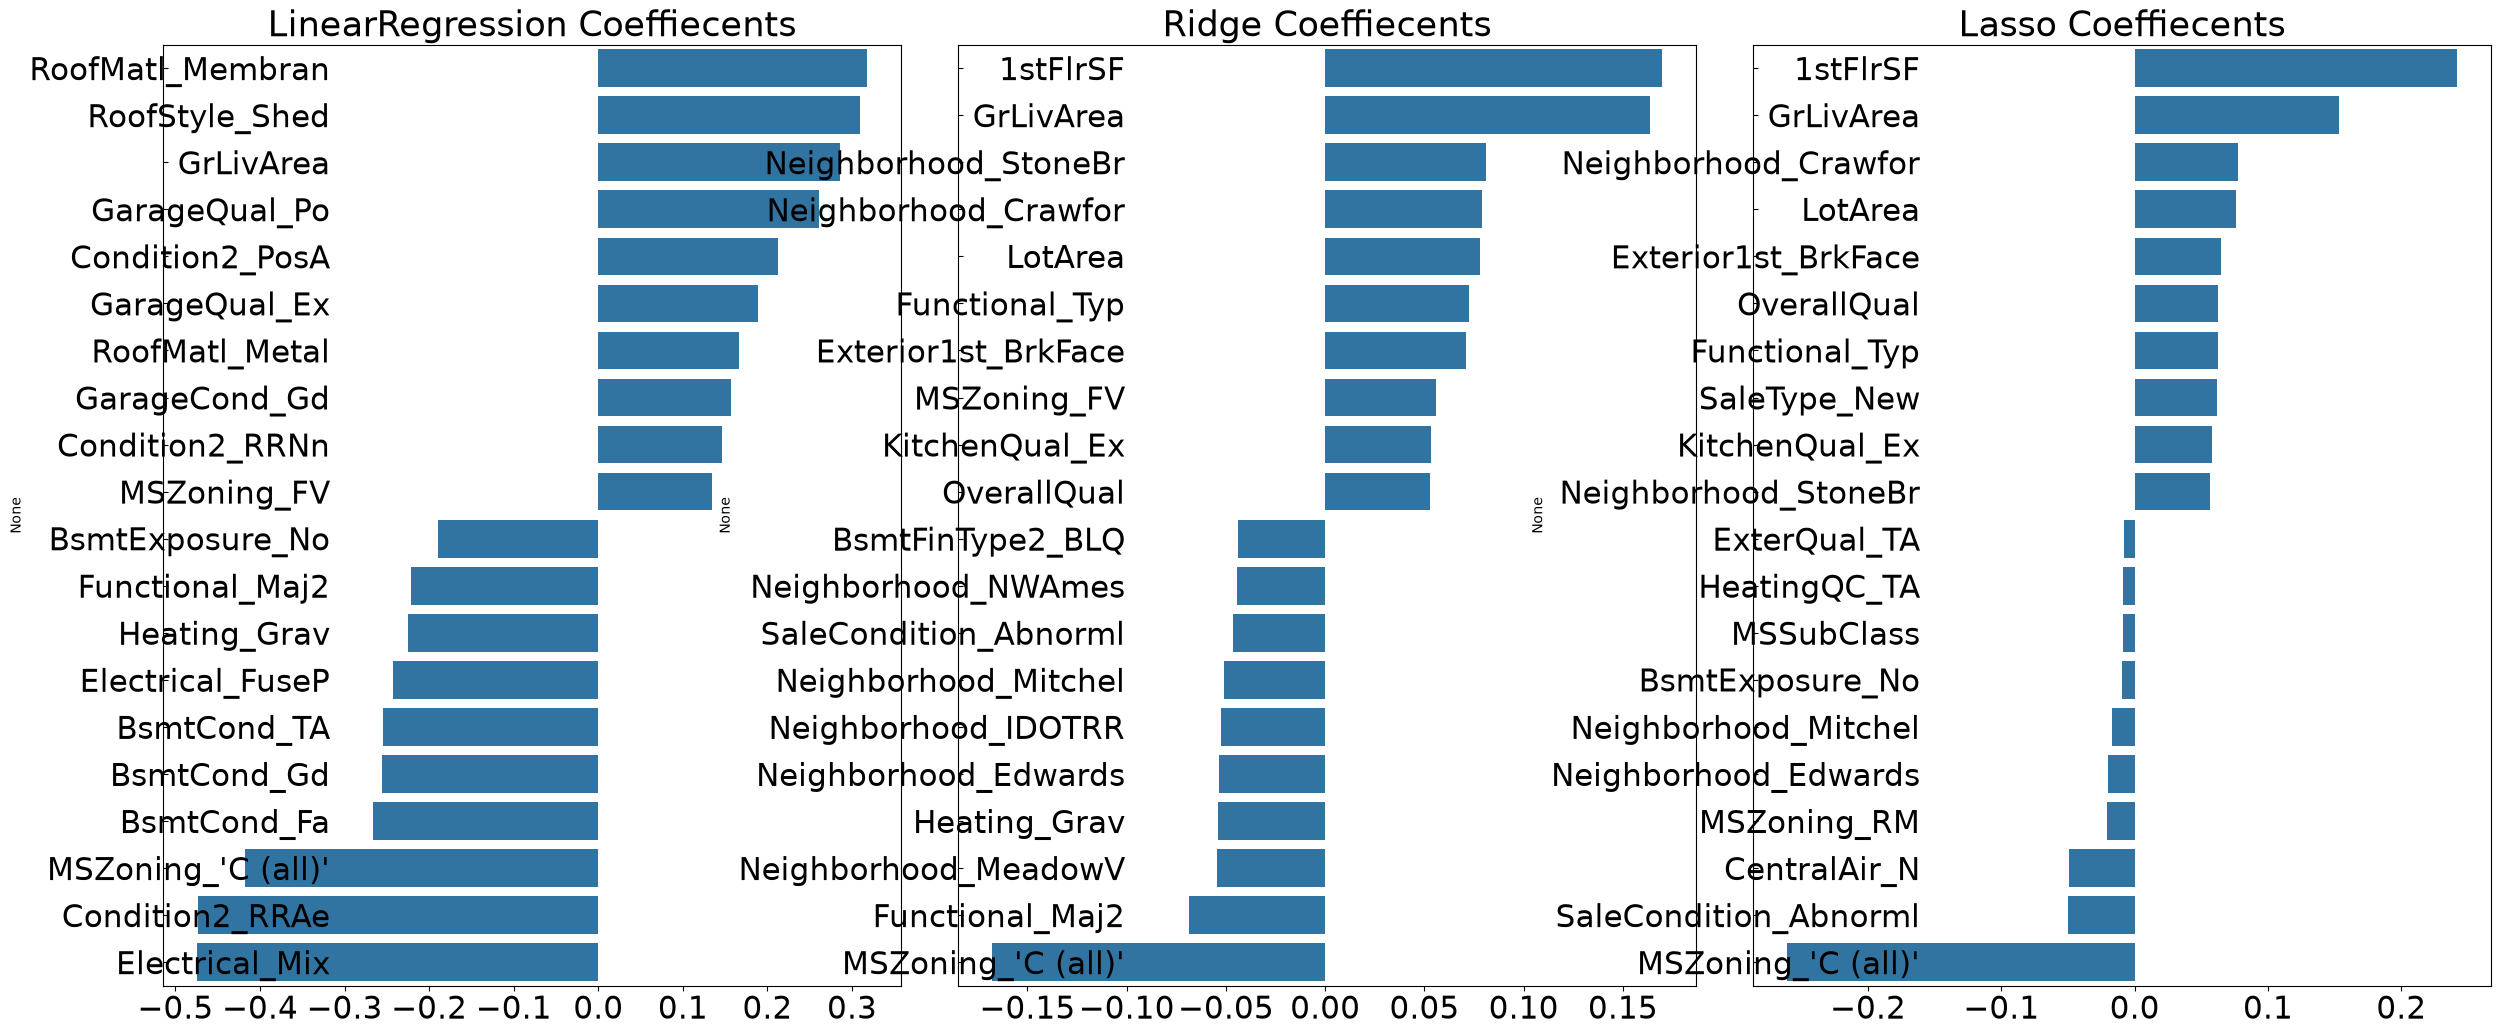

In [37]:
# 앞의 최적화 alpha값으로 학습데이터로 학습, 테스트 데이터로 예측 및 평가 수행. 
lr_reg = LinearRegression()
lr_reg.fit(X_train, y_train)
ridge_reg = Ridge(alpha=8)
ridge_reg.fit(X_train, y_train)
lasso_reg = Lasso(alpha=0.001)
lasso_reg.fit(X_train, y_train)

# 모든 모델의 RMSE 출력
models = [lr_reg, ridge_reg, lasso_reg]
get_rmses(models)

# 모든 모델의 회귀 계수 시각화 
models = [lr_reg, ridge_reg, lasso_reg]
visualize_coefficient(models)

2건을 지웠을 뿐인데 RMSE가 눈에 띄게 좋아진다. 선형 회귀는 제곱 오차를 최소화하므로
**멀리 떨어진 점 하나가 직선 전체를 끌어당긴다.** 미니프로젝트에서 극단값을 그대로 뒀던 것과
반대되는 선택인데, 그때는 트리 모델이라 극단값에 둔감했고 여기는 선형 모델이라서 다르다.

### 회귀 트리 학습/예측/평가 

In [38]:
from xgboost import XGBRegressor

xgb_params = {'n_estimators':[1000]}
xgb_reg = XGBRegressor(n_estimators=1000, learning_rate=0.05, 
                       colsample_bytree=0.5, subsample=0.8)
best_xgb = print_best_params(xgb_reg, xgb_params)

XGBRegressor 5 CV 시 최적 평균 RMSE 값: 0.1201, 최적 alpha:{'n_estimators': 1000}


In [39]:
from lightgbm import LGBMRegressor

lgbm_params = {'n_estimators':[1000]}
lgbm_reg = LGBMRegressor(n_estimators=1000, learning_rate=0.05, num_leaves=4, 
                         subsample=0.6, colsample_bytree=0.4, reg_lambda=10, n_jobs=-1)
best_lgbm = print_best_params(lgbm_reg, lgbm_params)

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001325 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3157
[LightGBM] [Info] Number of data points in the train set: 1166, number of used features: 172
[LightGBM] [Info] Start training from score 12.021352


[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001667 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3169
[LightGBM] [Info] Number of data points in the train set: 1166, number of used features: 169
[LightGBM] [Info] Start training from score 12.023516


[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.002490 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3163
[LightGBM] [Info] Number of data points in the train set: 1166, number of used features: 172
[LightGBM] [Info] Start training from score 12.020683


[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.002019 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3181
[LightGBM] [Info] Number of data points in the train set: 1167, number of used features: 169
[LightGBM] [Info] Start training from score 12.032713


[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001265 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3168
[LightGBM] [Info] Number of data points in the train set: 1167, number of used features: 172
[LightGBM] [Info] Start training from score 12.021807


[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.008612 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3436
[LightGBM] [Info] Number of data points in the train set: 1458, number of used features: 178
[LightGBM] [Info] Start training from score 12.024015


LGBMRegressor 5 CV 시 최적 평균 RMSE 값: 0.1163, 최적 alpha:{'n_estimators': 1000}


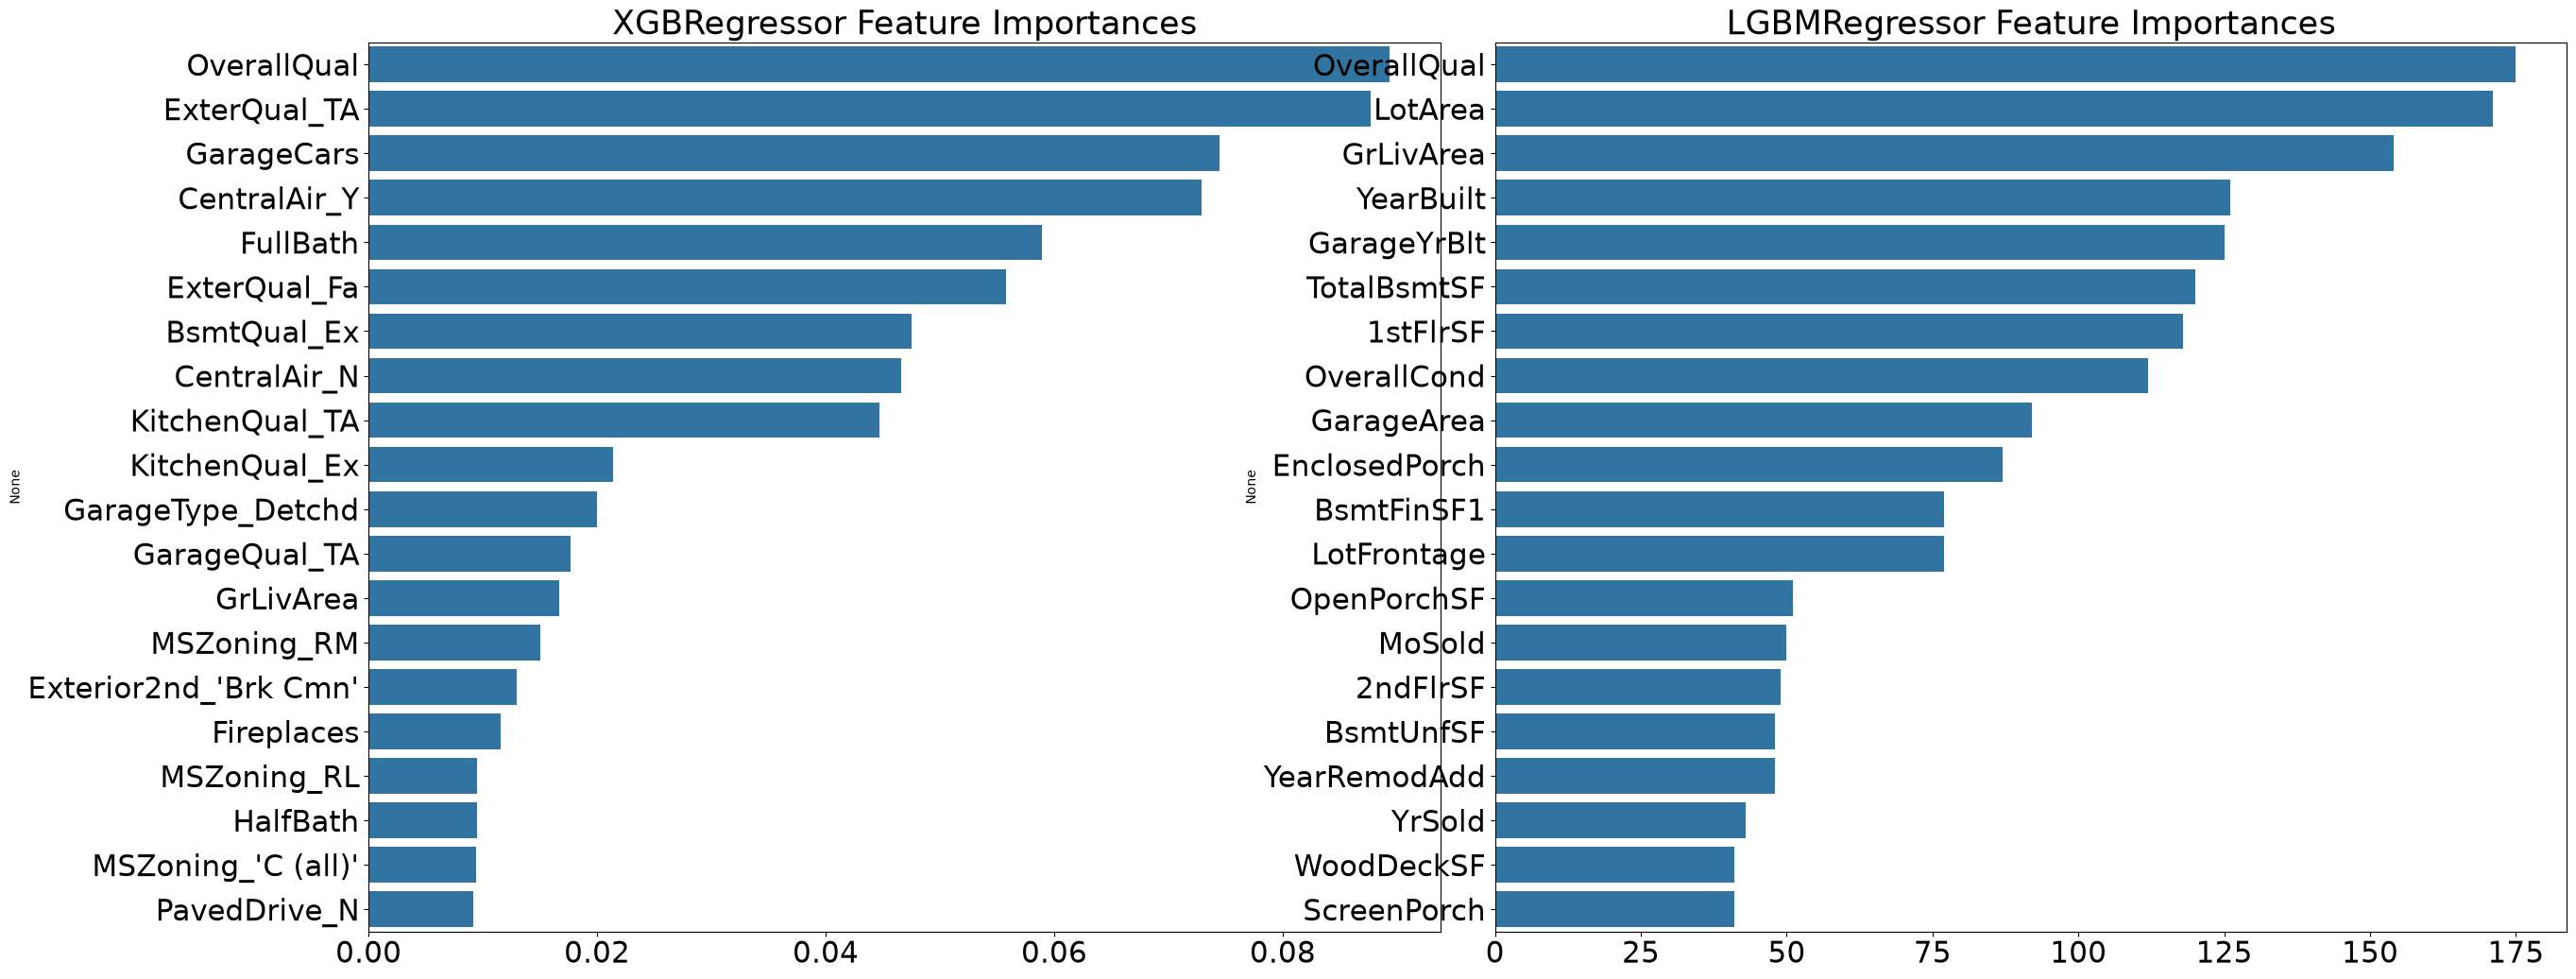

In [40]:
# 모델의 중요도 상위 20개의 피처명과 그때의 중요도값을 Series로 반환.
def get_top_features(model):
    ftr_importances_values = model.feature_importances_
    ftr_importances = pd.Series(ftr_importances_values, index=X_features.columns  )
    ftr_top20 = ftr_importances.sort_values(ascending=False)[:20]
    return ftr_top20

def visualize_ftr_importances(models):
    # 2개 회귀 모델의 시각화를 위해 2개의 컬럼을 가지는 subplot 생성
    fig, axs = plt.subplots(figsize=(24,10),nrows=1, ncols=2)
    fig.tight_layout() 
    # 입력인자로 받은 list객체인 models에서 차례로 model을 추출하여 피처 중요도 시각화. 
    for i_num, model in enumerate(models):
        # 중요도 상위 20개의 피처명과 그때의 중요도값 추출 
        ftr_top20 = get_top_features(model)
        axs[i_num].set_title(model.__class__.__name__+' Feature Importances', size=25)
        #font 크기 조정.
        for label in (axs[i_num].get_xticklabels() + axs[i_num].get_yticklabels()):
            label.set_fontsize(22)
        sns.barplot(x=ftr_top20.values, y=ftr_top20.index , ax=axs[i_num])

# 앞 예제에서 print_best_params( )가 반환한 GridSearchCV로 최적화된 모델의 피처 중요도 시각화    
models = [best_xgb, best_lgbm]
visualize_ftr_importances(models)


### 회귀 모델들의 예측 결과 혼합을 통한 최종 예측

In [41]:
def get_rmse_pred(preds):
    for key in preds.keys():
        pred_value = preds[key]
        mse = mean_squared_error(y_test , pred_value)
        rmse = np.sqrt(mse)
        print('{0} 모델의 RMSE: {1}'.format(key, rmse))

# 개별 모델의 학습
ridge_reg = Ridge(alpha=8)
ridge_reg.fit(X_train, y_train)
lasso_reg = Lasso(alpha=0.001)
lasso_reg.fit(X_train, y_train)
# 개별 모델 예측
ridge_pred = ridge_reg.predict(X_test)
lasso_pred = lasso_reg.predict(X_test)

# 개별 모델 예측값 혼합으로 최종 예측값 도출
pred = 0.4 * ridge_pred + 0.6 * lasso_pred
preds = {'최종 혼합': pred,
         'Ridge': ridge_pred,
         'Lasso': lasso_pred}
#최종 혼합 모델, 개별모델의 RMSE 값 출력
get_rmse_pred(preds)


최종 혼합 모델의 RMSE: 0.10007928539864393
Ridge 모델의 RMSE: 0.10345177546603244
Lasso 모델의 RMSE: 0.10024166367572426


릿지 0.4 + 라쏘 0.6으로 섞으니 각각보다 좋아진다.
**서로 조금씩 다르게 틀리기 때문에** 평균이 이득이 된다.

In [42]:
xgb_reg = XGBRegressor(n_estimators=1000, learning_rate=0.05, 
                       colsample_bytree=0.5, subsample=0.8)
lgbm_reg = LGBMRegressor(n_estimators=1000, learning_rate=0.05, num_leaves=4, 
                         subsample=0.6, colsample_bytree=0.4, reg_lambda=10, n_jobs=-1)
xgb_reg.fit(X_train, y_train)
lgbm_reg.fit(X_train, y_train)
xgb_pred = xgb_reg.predict(X_test)
lgbm_pred = lgbm_reg.predict(X_test)

pred = 0.5 * xgb_pred + 0.5 * lgbm_pred
preds = {'최종 혼합': pred,
         'XGBM': xgb_pred,
         'LGBM': lgbm_pred}
        
get_rmse_pred(preds)


[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001642 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3176
[LightGBM] [Info] Number of data points in the train set: 1166, number of used features: 173
[LightGBM] [Info] Start training from score 12.025343


최종 혼합 모델의 RMSE: 0.10042173668900717
XGBM 모델의 RMSE: 0.10491599513698831
LGBM 모델의 RMSE: 0.10408292148064811


### 스태킹 모델을 통한 회귀 예측

In [43]:
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error

# 개별 기반 모델에서 최종 메타 모델이 사용할 학습 및 테스트용 데이터를 생성하기 위한 함수. 
def get_stacking_base_datasets(model, X_train_n, y_train_n, X_test_n, n_folds ):
    # 지정된 n_folds값으로 KFold 생성.
    kf = KFold(n_splits=n_folds, shuffle=False)  # sklearn: shuffle=False면 random_state 불가
    #추후에 메타 모델이 사용할 학습 데이터 반환을 위한 넘파이 배열 초기화 
    train_fold_pred = np.zeros((X_train_n.shape[0] ,1 ))
    test_pred = np.zeros((X_test_n.shape[0],n_folds))
    print(model.__class__.__name__ , ' model 시작 ')
    
    for folder_counter , (train_index, valid_index) in enumerate(kf.split(X_train_n)):
        #입력된 학습 데이터에서 기반 모델이 학습/예측할 폴드 데이터 셋 추출 
        print('\t 폴드 세트: ',folder_counter,' 시작 ')
        X_tr = X_train_n[train_index] 
        y_tr = y_train_n[train_index] 
        X_te = X_train_n[valid_index]  
        
        #폴드 세트 내부에서 다시 만들어진 학습 데이터로 기반 모델의 학습 수행.
        model.fit(X_tr , y_tr)       
        #폴드 세트 내부에서 다시 만들어진 검증 데이터로 기반 모델 예측 후 데이터 저장.
        train_fold_pred[valid_index, :] = model.predict(X_te).reshape(-1,1)
        #입력된 원본 테스트 데이터를 폴드 세트내 학습된 기반 모델에서 예측 후 데이터 저장. 
        test_pred[:, folder_counter] = model.predict(X_test_n)
            
    # 폴드 세트 내에서 원본 테스트 데이터를 예측한 데이터를 평균하여 테스트 데이터로 생성 
    test_pred_mean = np.mean(test_pred, axis=1).reshape(-1,1)    
    
    #train_fold_pred는 최종 메타 모델이 사용하는 학습 데이터, test_pred_mean은 테스트 데이터
    return train_fold_pred , test_pred_mean

In [44]:
# get_stacking_base_datasets( )은 넘파이 ndarray를 인자로 사용하므로 DataFrame을 넘파이로 변환. 
X_train_n = X_train.values
X_test_n = X_test.values
y_train_n = y_train.values

# 각 개별 기반(Base)모델이 생성한 학습용/테스트용 데이터 반환. 
ridge_train, ridge_test = get_stacking_base_datasets(ridge_reg, X_train_n, y_train_n, X_test_n, 5)
lasso_train, lasso_test = get_stacking_base_datasets(lasso_reg, X_train_n, y_train_n, X_test_n, 5)
xgb_train, xgb_test = get_stacking_base_datasets(xgb_reg, X_train_n, y_train_n, X_test_n, 5)  
lgbm_train, lgbm_test = get_stacking_base_datasets(lgbm_reg, X_train_n, y_train_n, X_test_n, 5)



Ridge  model 시작 
	 폴드 세트:  0  시작 
	 폴드 세트:  1  시작 
	 폴드 세트:  2  시작 
	 폴드 세트:  3  시작 
	 폴드 세트:  4  시작 
Lasso  model 시작 
	 폴드 세트:  0  시작 
	 폴드 세트:  1  시작 
	 폴드 세트:  2  시작 


	 폴드 세트:  3  시작 
	 폴드 세트:  4  시작 
XGBRegressor  model 시작 
	 폴드 세트:  0  시작 


	 폴드 세트:  1  시작 


	 폴드 세트:  2  시작 


	 폴드 세트:  3  시작 


	 폴드 세트:  4  시작 


LGBMRegressor  model 시작 
	 폴드 세트:  0  시작 
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001536 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2926
[LightGBM] [Info] Number of data points in the train set: 932, number of used features: 157
[LightGBM] [Info] Start training from score 12.035561


	 폴드 세트:  1  시작 
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001572 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2953
[LightGBM] [Info] Number of data points in the train set: 933, number of used features: 163
[LightGBM] [Info] Start training from score 12.022847


	 폴드 세트:  2  시작 
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001608 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2942
[LightGBM] [Info] Number of data points in the train set: 933, number of used features: 159
[LightGBM] [Info] Start training from score 12.016965


	 폴드 세트:  3  시작 
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.002210 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2942
[LightGBM] [Info] Number of data points in the train set: 933, number of used features: 163
[LightGBM] [Info] Start training from score 12.023889


	 폴드 세트:  4  시작 
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001599 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2939
[LightGBM] [Info] Number of data points in the train set: 933, number of used features: 158
[LightGBM] [Info] Start training from score 12.027465


In [45]:
# 개별 모델이 반환한 학습 및 테스트용 데이터 세트를 Stacking 형태로 결합.  
Stack_final_X_train = np.concatenate((ridge_train, lasso_train, 
                                      xgb_train, lgbm_train), axis=1)
Stack_final_X_test = np.concatenate((ridge_test, lasso_test, 
                                     xgb_test, lgbm_test), axis=1)

# 최종 메타 모델은 라쏘 모델을 적용. 
meta_model_lasso = Lasso(alpha=0.0005)

#기반 모델의 예측값을 기반으로 새롭게 만들어진 학습 및 테스트용 데이터로 예측하고 RMSE 측정.
meta_model_lasso.fit(Stack_final_X_train, y_train)
final = meta_model_lasso.predict(Stack_final_X_test)
mse = mean_squared_error(y_test , final)
rmse = np.sqrt(mse)
print('스태킹 회귀 모델의 최종 RMSE 값은:', rmse)



스태킹 회귀 모델의 최종 RMSE 값은: 0.09737451959313702


스태킹이 가장 좋은 RMSE를 낸다. 네 모델의 예측값을 새 입력으로 삼아 라쏘로 한 번 더 학습한 구조다.
미니프로젝트의 최종 모델과 같은 발상이다.

## 5.11 정리

5장에서 다룬 것을 한 줄씩 정리한다.

| 절 | 내용 | 핵심 |
|---|---|---|
| 5.1~5.2 | 회귀 소개, 단순 선형 회귀 | 최적의 **회귀 계수**를 찾는 것이 목표. RSS를 최소화 |
| 5.3 | 경사 하강법 | 비용 함수를 편미분해 반대 방향으로 조금씩 이동 |
| 5.4 | 사이킷런 LinearRegression | 보스턴 주택 가격으로 학습·예측·평가 |
| 5.5 | 다항 회귀와 과적합 | 차수를 올릴수록 학습엔 맞고 새 데이터엔 틀림 |
| 5.6 | 규제 선형 모델 | 릿지(L2)는 계수를 줄이고, 라쏘(L1)는 0으로 만든다 |
| 5.7 | 로지스틱 회귀 | 이름은 회귀지만 **분류** 모델 |
| 5.8 | 회귀 트리 | 리프의 **평균**을 예측값으로. 예측선이 계단 모양 |
| 5.9~5.10 | 실습 두 건 | 전처리가 모델 선택만큼 점수를 좌우 |

두 실습을 관통하는 것은 **타깃과 변수의 분포를 손보는 일**이었다.
자전거는 `count`를 로그 변환하고 `year`·`hour`를 원-핫으로 바꿔서,
주택은 왜곡된 변수를 로그 변환하고 이상치 2건을 지워서 점수를 올렸다.
모델을 바꾸기 전에 데이터의 모양을 먼저 봤다는 점이 공통이다.

## 느낀 점

**평가 지표가 전처리를 결정한다.** 자전거 실습의 지표가 RMSLE였는데, 이건 예측값에 로그를
씌워 채점한다는 뜻이다. 그러면 학습할 때도 타깃을 로그로 바꿔 두는 쪽이 자연스럽다.
지표를 먼저 읽고 거기에 맞춰 데이터를 손봐야 한다는 걸 처음으로 분명히 알았다.
미니프로젝트의 지표는 정확도였는데, 그래서 확률을 평균 내고 argmax를 취하는 식으로
맞춰 갔던 것도 같은 맥락이었다.

**숫자처럼 생겼다고 숫자가 아니다.** 자전거 데이터의 `year`는 2011과 2012인데, 그대로 두면
모델이 "2012는 2011보다 1만큼 크다"로 읽는다. 원-핫 인코딩으로 바꾸자 RMSLE가 1.017에서
0.59까지 떨어졌다. 모델을 바꾼 것도 아니고 변수를 추가한 것도 아닌데 이만큼 움직였다.
와인 데이터에서 와인 종류를 0/1로 넣은 것은 값이 두 개뿐이라 괜찮았지만, 만약 등급 같은
변수가 입력에 있었다면 같은 실수를 했을 것 같다.

**이상치 2건이 1,460건짜리 모델을 흔들었다.** 주택 가격에서 거주 면적이 크면서 가격은 낮은
두 집을 지우자 RMSE가 눈에 띄게 좋아졌다. 선형 회귀는 오차를 제곱해서 더하니 멀리 떨어진
점 하나가 직선을 끌어당긴다는 설명이 숫자로 확인됐다. 미니프로젝트에서는 극단값을 그대로
뒀는데, 그때는 트리 모델이었고 트리는 값의 순서만 보기 때문에 영향이 없었다.
**같은 "이상치 처리"가 모델에 따라 필수이기도 하고 무의미하기도 하다.**

**결측치를 메우는 것과 변수를 버리는 것은 다른 판단이다.** 주택 데이터에서 `PoolQC`는 1,460건 중
1,453건이 비어 있었는데, 이건 기록 누락이 아니라 **수영장이 없다는 사실**이다. 그래서 평균으로
채우는 게 아니라 아예 지웠다. 반대로 `LotFrontage`처럼 259건 비어 있는 숫자형 변수는 평균으로
채웠다. 비어 있다는 사실 자체가 정보인지 아닌지를 먼저 봐야 한다.

**혼합과 스태킹이 여기서도 통했다.** 릿지와 라쏘를 0.4:0.6으로 섞은 것이 각각보다 좋았고,
네 모델을 스태킹한 것이 제일 좋았다. 미니프로젝트에서 랜덤 포레스트·ExtraTrees·스태킹을
1:1:1로 평균해 0.709를 만든 것과 구조가 같다. 다만 거기서 배운 것이 하나 더 있는데,
**섞어서 이득을 보려면 모델들이 서로 다르게 틀려야 한다**는 점이다. 이 실습에서도 릿지와
라쏘는 둘 다 선형이라 이득이 작았고, 성격이 다른 XGBoost·LightGBM까지 넣은 스태킹이
가장 좋았다.